### Northwind refund scenario

Northwind's wiki, `refund-policy.md`, says a refund over $200 needs a manager. It does not mention an enterprise exception.

In meeting `2026-03-12-refund-review`, Nandini says at 00:03:12 (192000 ms) that an enterprise ticket with code R-14 can be refunded up to $500 without a manager. Omar agrees, mark asks who owns the follow-up, and Nandini assigns it to Sam.

In [1]:
import json
from pathlib import Path

ROOT=Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
SCENARIO_DIR=ROOT/"data"/"scenario"

policy=(SCENARIO_DIR/"refund-policy.md").read_text(encoding="utf-8")
raw_meeting=json.loads((SCENARIO_DIR/"meeting.json").read_text(encoding="utf-8"))

policy

'# Refund policy\n\n## Standard limit\n\nA refund over $200 needs a manager\n\n'

In [2]:
assert "200" in policy
assert "manager" in policy

Nandini=next(turn for turn in raw_meeting["turns"] if "R-14" in turn["text"])
assert Nandini["speaker"] == "Nandini"
assert Nandini["start_ms"] == 192000
assert raw_meeting["meeting_id"] == "2026-03-12-refund-review"
assert len(raw_meeting["turns"]) == 4

Nandini

{'turn_id': 't1',
 'speaker': 'Nandini',
 'start_ms': 192000,
 'end_ms': 208000,
 'text': 'An enterprise ticket with code R-14 can be refunded up to $500 without a manager'}

### Records

A turn is the spoken sentence. A record is a decision or an action drawn from one or more turns. `turn_ids` must name turns that exist. The owner can be someone other than the speaker: Sam owns the follow-up, and Nandini said so on t4.

In [3]:
from typing import Literal
from pydantic import BaseModel, Field, ValidationError, model_validator

class Turn(BaseModel):
    turn_id: str
    speaker: str
    start_ms: int
    end_ms: int
    text: str

class Record(BaseModel):
    kind: Literal["decision", "problem", "action"]
    text: str
    owner: str
    turn_ids: list[str]=Field(min_length=1)

class Meeting(BaseModel):
    meeting_id: str
    turns: list[Turn]
    records: list[Record]=Field(default_factory=list)

    @model_validator(mode="after")
    def records_point_at_real_turns(self):
        known={turn.turn_id for turn in self.turns}
        for record in self.records:
            unknown=[turn_id for turn_id in record.turn_ids if turn_id not in known]
            if unknown:
                raise ValueError(f"Unknown turn_ids: {unknown}")
        return self

class Document(BaseModel):
    doc_id: str
    source_type: str
    title: str
    text: str
    section_path: str



In [4]:
meeting=Meeting.model_validate(raw_meeting)
wiki=Document(
    doc_id="refund-policy",
    source_type="wiki",
    title="Refund policy",
    text="A refund over $200 needs a manager",
    section_path="Standard limit",
)

meeting.records


[Record(kind='decision', text='An enterprise ticket with code R-14 can be refunded up to $500 without a manager', owner='Nandini', turn_ids=['t1']),
 Record(kind='action', text='Sam is the owner of the follow-up', owner='Sam', turn_ids=['t4'])]

In [5]:
bad= raw_meeting | {
    "records": [
        {
            "kind":"action",
            "text": "Sam is the owner of the follow-up",
            "owner": "Sam",
            "turn_ids": ["t9"]
        }
    ]
}

try:
    Meeting.model_validate(bad)
    raise AssertionError("t9 should have been rejected")
except ValidationError as e:
    print(e)


1 validation error for Meeting
  Value error, Unknown turn_ids: ['t9'] [type=value_error, input_value={'meeting_id': '2026-03-1...', 'turn_ids': ['t9']}]}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.14/v/value_error


### Chunks

A chunk is the piece search will rank. A turn chunk keeps the speaker and the timestamp on the same sentence. A topic chunk keeps a few turns together for context. A record chunk is a decision or action and still points at the turns it came from. A section chunk is one wiki heading.

In [6]:
def format_ms(ms: int) -> str:
    total_seconds=ms // 1000
    hours=total_seconds // 3600
    minutes=(total_seconds % 3600) // 60
    seconds=total_seconds % 60
    return f"{hours}:{minutes:02d}:{seconds:02d}"

class Chunk(BaseModel):
    chunk_id: str
    text: str
    source_type: str
    unit: Literal["turn", "topic", "record", "section"]
    citation: dict



In [8]:
def chunk_meeting(meeting: Meeting)->list[Chunk]:
    turn_chunks=[]
    for turn in meeting.turns:
        stamp=format_ms(turn.start_ms)
        turn_chunks.append(
            Chunk(
                chunk_id=f"turn:{meeting.meeting_id}:{turn.turn_id}",
                text=f"{turn.speaker} ({stamp}):{turn.text}",
                source_type="meeting",
                unit="turn",
                citation={
                    "meeting_id": meeting.meeting_id,
                    "turn_id":turn.turn_id,
                    "speaker":turn.speaker,
                    "start_ms": turn.start_ms,
                    "end_ms":turn.end_ms,
                    "timestamp": stamp,
                },
            )
        )
    
    topic_chunks=[]
    window=3
    for start in range(0, len(turn_chunks)-window+1):
        group=turn_chunks[start: start+window]
        first=group[0].citation["turn_id"]
        last=group[-1].citation["turn_id"]
        topic_chunks.append(
            Chunk(
                chunk_id=f"topic:{meeting.meeting_id}:{first}-{last}",
                text="\n".join(chunk.text for chunk in group),
                source_type="meeting",
                unit="topic",
                citation={
                    "meeting_id": meeting.meeting_id,
                    "turns_ids": [chunk.citation["turn_id"] for chunk in group],
                },
            )
        )
    
    record_chunks=[]
    for record in meeting.records:
        joined="-".join(record.turn_ids)
        record_chunks.append(
            Chunk(
                chunk_id=f"record:{meeting.meeting_id}: {record.kind}:{joined}",
                text=f"{record.kind} by {record.owner}: {record.text}",
                source_type="meeting",
                unit="record",
                citation={
                    "meeting_id": meeting.meeting_id,
                    "kind":record.kind, 
                    "owner":record.owner,
                    "turn_ids": record.turn_ids,
                }
            )
        )
    
    return turn_chunks+topic_chunks+record_chunks

def chunk_document(document: Document)->Chunk:
    slug=document.section_path.lower().replace(" ","-")
    return Chunk(
        chunk_id=f"section:{document.doc_id}:{slug}",
        text=f"{document.section_path}: {document.text}",
        source_type=document.source_type,
        unit="section",
        citation={
            "doc_id": document.doc_id,
            "section_path": document.section_path,
        }
    )


In [9]:
chunks = chunk_meeting(meeting) + [chunk_document(wiki)]

r14 = next(chunk for chunk in chunks if chunk.unit == "turn" and "R-14" in chunk.text)
assert "Nandini" in r14.text
assert r14.citation["speaker"] == "Nandini"
assert r14.citation["start_ms"] == 192000

policy_chunk = next(chunk for chunk in chunks if chunk.unit == "section")
assert "200" in policy_chunk.text
assert policy_chunk.citation["section_path"] == "Standard limit"

assert {chunk.unit for chunk in chunks} == {"turn", "topic", "record", "section"}
# r14
policy_chunk

Chunk(chunk_id='section:refund-policy:standard-limit', text='Standard limit: A refund over $200 needs a manager', source_type='wiki', unit='section', citation={'doc_id': 'refund-policy', 'section_path': 'Standard limit'})

### Keyword search

BM25 ranks chunks by shared words. `R-14` has to match as a whole token, not as the separate letters R and 14. A score of 0 means the query and the chunk share nothing, so `Z-99` should return no hits.

In [10]:
import re
from rank_bm25 import BM25Okapi

def tokenize(text: str)->list[str]:
    return re.findall(r"[a-z0-9]+(?:-[a-z0-9]+)*", text.lower())

class BM25Index:
    def __init__(self,chunks:list[Chunk]):
        self.chunks=[chunk for chunk in chunks if chunk.unit != "topic"]
        corpus=[tokenize(chunk.text) for chunk in self.chunks]
        self.engine=BM25Okapi(corpus)

    def search(self, query:str, k:int=5)->list[tuple[Chunk, float]]:
        tokens=tokenize(query)
        if not tokens:
            return []
        scores=self.engine.get_scores(tokens)
        ranked=sorted(
            zip(self.chunks,scores),
            key=lambda pair: pair[1],
            reverse=True,
        )
        return [
            (chunk, float(score))
            for chunk,score in ranked[:k]
            if score>0
        ]


In [11]:
index=BM25Index(chunks)
hits=index.search("enterprise R-14 refund owner")

for chunk, score in hits:
    print(f"{score:.3f} {chunk.unit:8} {chunk.chunk_id}")

hit_ids={chunk.chunk_id for chunk,_ in hits}
assert any(chunk_id.startswith("turn:") and "t1" in chunk_id for chunk_id in hit_ids)
assert any(chunk.unit == "record" and "action" in chunk.chunk_id for chunk, _ in hits)
missing = index.search("Z-99")
assert missing == []
missing

1.645 section  section:refund-policy:standard-limit
1.279 record   record:2026-03-12-refund-review: decision:t1
1.241 turn     turn:2026-03-12-refund-review:t1
0.848 record   record:2026-03-12-refund-review: action:t4
0.815 turn     turn:2026-03-12-refund-review:t4


[]

### Cited answer

`answer_from_hits` does not write new facts. Each sentence is the text of a retrieved chunk, plus that chunk's citation. The top BM25 score on a real hit here is about 1.6, and the weakest hit in the top 5 is about 0.8, so a minimum score of 0.5 keeps those hits and drops anything weaker. No hits means the code was not in the sources.

In [12]:
class CitedSentence(BaseModel):
    text:str
    chunk_id: str
    citation: dict

class CitedAnswer(BaseModel):
    abstained: bool
    message: str
    sentences: list[CitedSentence]

def answer_from_hits(question: str, hits: list[tuple[Chunk, float]],min_score:float=0.5,)->CitedAnswer:
    if not hits or hits[0][1]<min_score:
        return CitedAnswer(
            abstained=True,
            message="not in the sources",
            sentences=[],
        )
    sentences=[
        CitedSentence(
            text=chunk.text,
            chunk_id=chunk.chunk_id,
            citation=chunk.citation,
        )
        for chunk, _ in hits
    ]
    return CitedAnswer(abstained=False, message="", sentences=sentences)


In [13]:
refund_question=("Can we refund $400 on and enterprise R-14 ticket, and who owns the follow-up?")
refund_hits=index.search(refund_question)
refund_answer=answer_from_hits(refund_question, refund_hits)
refund_answer


CitedAnswer(abstained=False, message='', sentences=[CitedSentence(text='Mark (0:03:44):Who owns the follow-up?', chunk_id='turn:2026-03-12-refund-review:t3', citation={'meeting_id': '2026-03-12-refund-review', 'turn_id': 't3', 'speaker': 'Mark', 'start_ms': 224000, 'end_ms': 232000, 'timestamp': '0:03:44'}), CitedSentence(text='decision by Nandini: An enterprise ticket with code R-14 can be refunded up to $500 without a manager', chunk_id='record:2026-03-12-refund-review: decision:t1', citation={'meeting_id': '2026-03-12-refund-review', 'kind': 'decision', 'owner': 'Nandini', 'turn_ids': ['t1']}), CitedSentence(text='Nandini (0:03:12):An enterprise ticket with code R-14 can be refunded up to $500 without a manager', chunk_id='turn:2026-03-12-refund-review:t1', citation={'meeting_id': '2026-03-12-refund-review', 'turn_id': 't1', 'speaker': 'Nandini', 'start_ms': 192000, 'end_ms': 208000, 'timestamp': '0:03:12'}), CitedSentence(text='Standard limit: A refund over $200 needs a manager', c

### Hybrid search

BM25 and vector search each return a ranked list. Reciprocal rank fusion scores a chunk by its place in each list: `1 / (60 + rank)`. Rank 1 is worth `1/61`. A chunk that appears on both lists adds both scores. Topic chunks stay out of both lists.

In [14]:
import numpy as np
from langchain_huggingface import HuggingFaceEmbeddings

embedder= HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
)

def searchable(chunks:list[Chunk])->list[Chunk]:
    return [chunk for chunk in chunks if chunk.unit != 'topic']

def cosine_scores(query: np.ndarray, documents:np.ndarray)->np.ndarray:
    query_norm=query/(np.linalg.norm(query)+ 1e-9)
    document_norms=np.linalg.norm(documents, axis=1, keepdims=True)+1e-9
    return (documents/document_norms) @ query_norm

def vector_search(chunks: list[Chunk],query:str,k:int=5)->list[Chunk]:
    choosen_chunks=searchable(chunks)
    document_vectors=np.array(embedder.embed_documents([chunk.text for chunk in choosen_chunks]))
    query_vector=np.array(embedder.embed_query(query))
    scores=cosine_scores(query_vector, document_vectors)
    order=np.argsort(-scores)
    return [choosen_chunks[int(i)] for i in order[:k]]

def reciprocal_rank_fusion(rankings: list[list[str]], k:int=5)->list[tuple[str,float]]:
    scores: dict[str, float]={}
    for ranking in rankings:
        for rank, chunk_id in enumerate(ranking, start=1):
            scores[chunk_id]=scores.get(chunk_id,0.0)+1.0/(k+rank)
    return sorted(scores.items(), key=lambda item: item[1],reverse=True)



c:\Users\NANDINI\Desktop\VoiceAgent\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2930.53it/s]


In [15]:
paraphrase = (
    "Is a supervisor required for a large enterprise credit on ticket R-14?"
)

bm25_hits=[chunk.chunk_id for chunk, _ in index.search(paraphrase)]
vector_hits=[chunk.chunk_id for chunk in vector_search(chunks, paraphrase)]
fused= reciprocal_rank_fusion([bm25_hits, vector_hits])


print("BM25")
for chunk_id in bm25_hits:
    print(" ", chunk_id)
print("Vector")
for chunk_id in vector_hits:
    print(" ", chunk_id)
print("Fused")
for chunk_id, score in fused[:5]:
    print(f"{score:.4f} {chunk_id}")

fused_top=[chunk_id for chunk_id,_ in fused[:5]]




BM25
  record:2026-03-12-refund-review: decision:t1
  turn:2026-03-12-refund-review:t1
  record:2026-03-12-refund-review: action:t4
  turn:2026-03-12-refund-review:t4
  section:refund-policy:standard-limit
Vector
  record:2026-03-12-refund-review: decision:t1
  turn:2026-03-12-refund-review:t1
  section:refund-policy:standard-limit
  turn:2026-03-12-refund-review:t2
  record:2026-03-12-refund-review: action:t4
Fused
0.3333 record:2026-03-12-refund-review: decision:t1
0.2857 turn:2026-03-12-refund-review:t1
0.2250 record:2026-03-12-refund-review: action:t4
0.2250 section:refund-policy:standard-limit
0.1111 turn:2026-03-12-refund-review:t4


### Rerank and citation check

Fusion returns a wide list. The cross-encoder scores each question-chunk pair and keeps four chunks inside a word budget. The answer may cite only those chunk ids. A citation that was not retrieved, or a number that is not in the cited text, is an error.

In [16]:
from sentence_transformers import CrossEncoder

reranker=CrossEncoder("BAAI/bge-reranker-base")
chunks_by_id = {chunk.chunk_id: chunk for chunk in searchable(chunks)}
chunks_by_id

def fit_word_budget(ranked: list[Chunk], limit:int=4, budget:int=80)->list[Chunk]:
    kept: list[Chunk]=[]
    used=0
    for chunk in ranked:
        cost=len(tokenize(chunk.text))
        if kept and used+cost > budget:
            continue
        kept.append(chunk)
        used+=cost
        if len(kept)>=limit:
            break
    return kept

def rerank(question: str, fused_ids:list[str])->list[Chunk]:
    candidates=[chunks_by_id[chunk_id] for chunk_id in fused_ids[:20]]
    pairs=[(question, chunk.text) for chunk in candidates]
    scores=reranker.predict(pairs)
    order = np.argsort(-np.array(scores))
    ranked = [candidates[int(i)] for i in order]
    return fit_word_budget(ranked)


c:\Users\NANDINI\Desktop\VoiceAgent\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\NANDINI\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\NANDINI\Desktop\VoiceAgent\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache

check_citations is the gate after the model writes. Retrieval and reranking choose the evidence. This function checks that the answer actually stayed inside that evidence.

In [29]:
# class CitedSentence(BaseModel):
#     text:str
#     chunk_id: str
#     citation: dict

# class CitedAnswer(BaseModel):
#     abstained: bool
#     message: str
#     sentences: list[CitedSentence]

def check_citations(answer: CitedAnswer, allowed_list: set[str])->list[str]:
    if answer.abstained:
        return []
    errors: list[str]=[]
    for sentence in answer.sentences:
        if sentence.chunk_id not in allowed_list:
            errors.append(f"invented citation: {sentence.chunk_id}")
            continue
        source_tokens=set(tokenize(chunks_by_id[sentence.chunk_id].text))
        claim_tokens=[
            token
            for token in tokenize(sentence.text)
            if any(character.isdigit() for character in token) or len(token)>3
        ]
        missing=[token for token in claim_tokens if token not in source_tokens]
        if missing:
            errors.append(f"unsupported {missing} in {sentence.chunk_id}")
    return errors

invented=CitedAnswer(
    abstained=False,
    message="",
    sentences=[
        CitedSentence(
            text="The cap is $9000",
            chunk_id="turn:2026-03-12-refund-review:t1",
            citation={}
            
        )
    ],
)
invented_errors=check_citations(invented, set(chunks_by_id.keys()))
invented_errors



["unsupported ['9000'] in turn:2026-03-12-refund-review:t1"]

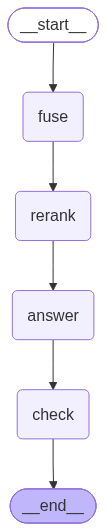

In [27]:
import os
from typing import TypedDict
from langgraph.graph import END, START, StateGraph
from langchain_openai import ChatOpenAI

class GraphState(TypedDict):
    question: str
    fused_ids: list[str]
    chosen_ids: list[str]
    answer:dict
    errors:list[str]

def node_fuse(state: GraphState)->dict:
    question=state["question"]
    bm25_ids=[chunk.chunk_id for chunk, _ in index.search(question, k=20)]
    vector_ids=[chunk.chunk_id for chunk in vector_search(chunks,question, k=20)]
    fused_ids=[chunk_id for chunk_id,_ in reciprocal_rank_fusion([bm25_ids,vector_ids])]
    return {"fused_ids": fused_ids}

def node_rerank(state: GraphState) -> dict:
    chosen=rerank(state["question"], state["fused_ids"])
    return {"chosen_ids": [chunk.chunk_id for chunk in chosen]}

def node_answer(state: GraphState)->dict:
    chosen=[chunks_by_id[chunk_id] for chunk_id in state["chosen_ids"]]
    if not chosen:
        answer=CitedAnswer(abstained=True,message="not in the sources", setences=[])
        return {"answer": answer.model_dump()}
    if not os.environ.get("OPENAI_API_KEY"):
        hits = [(chunk,1.0) for chunk in chosen]
        answer=answer_from_hits(state["question"], hits,min_score=0.0)
        return {"answer": answer.model_dump()}

    catalog="\n".join(
            f"{chunk.chunk_id}: {chunk.text}" for chunk in chosen
    )

    prompt=(
        "Answer only from the chunks below."
        "Return JSON with key sentences, a list of objects with keys text and chunk_d"
        "Every chunk_id must be copied from the list. If the chunks do not contain the answer, "
        "return {\"abstained\": true, \"message\": \"not in the sources\", \"sentences\": []}.\n\n"
        f"Question: {state['question']}\n\n{catalog}"
    )

    raw=ChatOpenAI(model="gpt-4o-mini", temperature=0.0).invoke(prompt).content
    return {"answer": CitedAnswer.model_validate(raw).model_dump()}

def node_check(state: GraphState)->dict:
    answer=CitedAnswer.model_validate(state["answer"])
    return {"errors": check_citations(answer, set(chunks_by_id.keys()))}

graph_builder=StateGraph(GraphState)
graph_builder.add_node("fuse", node_fuse)
graph_builder.add_node("rerank", node_rerank)
graph_builder.add_node("answer", node_answer)
graph_builder.add_node("check", node_check)

graph_builder.set_entry_point("fuse")
graph_builder.add_edge(START, "fuse")
graph_builder.add_edge("fuse", "rerank")
graph_builder.add_edge("rerank", "answer")
graph_builder.add_edge("answer", "check")
graph_builder.add_edge("check", END)

search_graph=graph_builder.compile()

result=search_graph.invoke({"question": refund_question})
answer=CitedAnswer.model_validate(result["answer"])

result["chosen_ids"],answer, result["errors"]
            
        
from IPython.display import Image, display
display(Image(search_graph.get_graph().draw_mermaid_png()))
